# 04 - Graph Neural Networks for illicit wallet detection

GCN and GraphSAGE node classifiers on the Elliptic++ **address-address** graph, compared against an XGBoost baseline that sees the *same* 7 node features and the *same* train/val/test split. The only thing that differs between the baseline and the GNNs is message passing.

**Inputs:** `../outputs/results/wallet_graph_features_with_labels.csv` (from notebook 02) and `../data/AddrAddr_edgelist.csv`
**Outputs:** `../outputs/models/`, `../outputs/results/gnn_*.csv`, `../outputs/plots/gnn_*.png` (consumed by `05_results.ipynb`)

# Setup

In [33]:
# Run once if the packages are missing (uncomment).
# CPU-only PyTorch:  %pip install torch --index-url https://download.pytorch.org/whl/cpu
# %pip install torch-geometric xgboost seaborn scikit-learn

In [34]:
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv, SAGEConv
from torch_geometric.utils import remove_self_loops, subgraph, to_undirected

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import QuantileTransformer
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from xgboost import XGBClassifier

SEED = 42


def set_seed(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


# Config

In [35]:
# True : message passing over ALL 822,942 wallets (unlabeled wallets act as context). Recommended.
# False: message passing only over the 265,354 labeled wallets. Lighter on RAM, but throws away ~60% of the edges.
USE_FULL_GRAPH = True

HIDDEN = 64
DROPOUT = 0.3
LR = 0.005
WEIGHT_DECAY = 5e-4
MAX_EPOCHS = 150
PATIENCE = 25      # early stopping on validation PR-AUC of the illicit class

# Paths

In [36]:
RESULTS_PATH = Path("../outputs/results")
MODEL_PATH = Path("../outputs/models")
FIGURE_PATH = Path("../outputs/plots")
DATA_PATH = Path("../data")

for p in (RESULTS_PATH, MODEL_PATH, FIGURE_PATH):
    p.mkdir(parents=True, exist_ok=True)

graph_csv = RESULTS_PATH / "wallet_graph_features_with_labels.csv"
edge_csv = DATA_PATH / "AddrAddr_edgelist.csv"

print("Graph file exists:", graph_csv.exists())
print("Edge file exists: ", edge_csv.exists())

Graph file exists: True
Edge file exists:  True


# Load data

In [37]:
graph_df = pd.read_csv(graph_csv)
edge_df = pd.read_csv(edge_csv)

print("Wallet data:", graph_df.shape)
print("Edge data:  ", edge_df.shape)

assert graph_df["address"].is_unique, "Duplicate wallet addresses in the feature file"
graph_df.head()

Wallet data: (822942, 9)
Edge data:   (2868964, 2)


,address,in_degree,out_degree,total_degree,degree_centrality,num_predecessors,num_successors,num_neighbors,class
0,13vHWR3iLsHeYwT42RnuKYNBoVPrKKZgRv,2198,1370,3568,0.004336,2198,1370,3553,2
1,1P9RQEr2XeE3PEb44ZE35sfZRRW1JHU8qx,3,1183,1186,0.001441,3,1183,1185,3
2,366Dgw4pi3rnvu5zizVWZF6nijWxZWc6RA,210,782,992,0.001205,210,782,991,3
3,1FoxBitjXcBeZUS4eDzPZ7b124q3N7QJK7,7,828,835,0.001015,7,828,834,2
4,33fjpQKTzzyQWu6T4PcXUxgbqRbd618u8U,1,575,576,0.000700,1,575,575,3


In [38]:
edge_df.head()

,input_address,output_address
0,14YRXHHof4BY1TVxN5FqYPcEdpmXiYT78a,1GASxu5nMntiRKdVtTVRvEbP965G51bhHH
1,14YRXHHof4BY1TVxN5FqYPcEdpmXiYT78a,14YRXHHof4BY1TVxN5FqYPcEdpmXiYT78a
2,13Lhad3SAmu2vqYg2dxbNcxH7LE77kJu2w,1GFdrdgtG34GChM8SMpMwcXFc4nYbH1A5G
3,1MAQQZn7EHP6J3erXByCciFiVcgS8ZhWqz,19q57SeCEzTnWrWVXA43nZzhSiXkYggh7c
4,1MAQQZn7EHP6J3erXByCciFiVcgS8ZhWqz,1Kk1NVYnCE8ALXDhgMM6HqTt1jDSvi6QBA


# Prepare nodes and labels

Elliptic++ wallet classes are **1 = illicit, 2 = licit, 3 = unknown**. The previous version of this notebook mapped them the other way round, so every "illicit" metric was actually measuring the licit majority class (a 91% / 9% test split reported as "Illicit / Licit"). The assertion below guards against that.

In [39]:
feature_cols = [
    "in_degree",
    "out_degree",
    "total_degree",
    "degree_centrality",
    "num_predecessors",
    "num_successors",
    "num_neighbors",
]

missing = [c for c in feature_cols + ["address", "class"] if c not in graph_df.columns]
assert not missing, f"Missing columns: {missing}"

LABEL_MAP = {1: 1, 2: 0}   # class 1 (illicit) -> 1, class 2 (licit) -> 0, class 3 (unknown) -> NaN

label_series = graph_df["class"].map(LABEL_MAP)
labeled_mask_np = label_series.notna().to_numpy(copy=True)
y_all = label_series.fillna(-1).astype(np.int64).to_numpy(copy=True)   # -1 = unknown, never used for loss or metrics

n_labeled = int(labeled_mask_np.sum())
n_illicit = int((y_all == 1).sum())
print(f"Labeled wallets : {n_labeled:,}")
print(f"  illicit (1)   : {n_illicit:,} ({n_illicit / n_labeled:.2%})")
print(f"  licit   (0)   : {n_labeled - n_illicit:,}")
print(f"Unlabeled wallets: {len(graph_df) - n_labeled:,}")

assert 0 < n_illicit / n_labeled < 0.5, "Illicit must be the minority class - check LABEL_MAP"

node_index = pd.Index(graph_df["address"].astype(str))   # row position == node id

Labeled wallets : 265,354
  illicit (1)   : 14,266 (5.38%)
  licit   (0)   : 251,088
Unlabeled wallets: 557,588


# Train / validation / test split

Stratified random 70/15/15 split over the labeled wallets, the same scheme as `03_train_models.ipynb`.

The previous connected-component split is dropped: one giant component swallowed almost everything, giving 14.6k train / 230k val / 3.1k test wallets instead of 70/15/15.

In [40]:
labeled_idx = np.flatnonzero(labeled_mask_np)

train_idx, temp_idx = train_test_split(
    labeled_idx, test_size=0.30, stratify=y_all[labeled_idx], random_state=SEED
)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, stratify=y_all[temp_idx], random_state=SEED
)

# Sorted so that "mask order" and "index order" are identical everywhere below.
train_idx, val_idx, test_idx = np.sort(train_idx), np.sort(val_idx), np.sort(test_idx)

for name, idx in [("Train", train_idx), ("Val", val_idx), ("Test", test_idx)]:
    print(f"{name:5s}: {len(idx):>8,} wallets | illicit {y_all[idx].mean():.2%}")

assert len(np.intersect1d(train_idx, val_idx)) == 0
assert len(np.intersect1d(train_idx, test_idx)) == 0
assert len(np.intersect1d(val_idx, test_idx)) == 0
print("Split check passed.")

Train:  185,747 wallets | illicit 5.38%
Val  :   39,803 wallets | illicit 5.38%
Test :   39,804 wallets | illicit 5.38%
Split check passed.


# Feature scaling

Degree features are extremely heavy-tailed (hubs have 10,000+ edges, most wallets have 1-3). Unscaled, they make GCN/GraphSAGE training unstable. A quantile transform (to a normal distribution) is fit on the **training wallets only** and then applied to every wallet.

In [41]:
X_raw = graph_df[feature_cols].to_numpy(dtype=np.float64)

scaler = QuantileTransformer(
    n_quantiles=1000,
    output_distribution="normal",
    subsample=int(1e6),
    random_state=SEED,
)
scaler.fit(X_raw[train_idx])
X = scaler.transform(X_raw).astype(np.float32)

print("Scaled feature matrix:", X.shape)
print(f"Scaled value range: [{X.min():.2f}, {X.max():.2f}]  (NaNs: {int(np.isnan(X).sum())})")

Scaled feature matrix: (822942, 7)
Scaled value range: [-5.20, 5.20]  (NaNs: 0)


# Build edge index

* Raw self-loops and duplicate edges are removed, then the graph is made undirected.
* No manual self-loops: `GCNConv` adds its own, and `SAGEConv` has a separate root weight (extra self-loops would blur it into the neighbour mean).

In [42]:
src_col, dst_col = edge_df.columns[:2]

src = node_index.get_indexer(edge_df[src_col].astype(str))
dst = node_index.get_indexer(edge_df[dst_col].astype(str))
keep = (src >= 0) & (dst >= 0)
print(f"Edges with both wallets in the feature file: {keep.sum():,} / {len(keep):,}")

edge_index = torch.from_numpy(np.vstack([src[keep], dst[keep]])).long()
n_raw = edge_index.size(1)

edge_index, _ = remove_self_loops(edge_index)
edge_index = to_undirected(edge_index, num_nodes=len(graph_df))   # also coalesces duplicates

print(f"Raw directed edges: {n_raw:,}")
print(f"Final undirected edge_index: {edge_index.size(1):,} (both directions stored)")

Edges with both wallets in the feature file: 2,868,964 / 2,868,964
Raw directed edges: 2,868,964
Final undirected edge_index: 5,544,948 (both directions stored)


# Create PyG Data object

In [43]:
N = len(graph_df)


def to_mask(idx: np.ndarray, n: int) -> torch.Tensor:
    m = torch.zeros(n, dtype=torch.bool)
    m[torch.as_tensor(idx)] = True
    return m


x_all = torch.from_numpy(X)
y_t = torch.from_numpy(y_all)

if USE_FULL_GRAPH:
    ei, xs, ys = edge_index, x_all, y_t
    tr, va, te = train_idx, val_idx, test_idx
else:
    # Keep only labeled wallets. labeled_idx is sorted, so new id == position in labeled_idx.
    keep_nodes = torch.from_numpy(labeled_idx)
    ei, _ = subgraph(keep_nodes, edge_index, relabel_nodes=True, num_nodes=N)
    xs, ys = x_all[keep_nodes], y_t[keep_nodes]
    new_id = np.full(N, -1, dtype=np.int64)
    new_id[labeled_idx] = np.arange(len(labeled_idx))
    tr, va, te = new_id[train_idx], new_id[val_idx], new_id[test_idx]

data = Data(x=xs, edge_index=ei, y=ys)
data.train_mask = to_mask(tr, data.num_nodes)
data.val_mask = to_mask(va, data.num_nodes)
data.test_mask = to_mask(te, data.num_nodes)

assert not (data.train_mask & data.val_mask).any()
assert not (data.train_mask & data.test_mask).any()
assert not (data.val_mask & data.test_mask).any()
for m in (data.train_mask, data.val_mask, data.test_mask):
    assert (data.y[m] >= 0).all(), "Unlabeled wallet leaked into a split"

data = data.to(device)
print(data)
print("Train / val / test nodes:",
      int(data.train_mask.sum()), int(data.val_mask.sum()), int(data.test_mask.sum()))

# Class weights from the TRAIN labels only (inverse frequency for the minority class)
n_pos = int((data.y[data.train_mask] == 1).sum())
n_neg = int((data.y[data.train_mask] == 0).sum())
class_weights = torch.tensor([1.0, n_neg / n_pos], dtype=torch.float, device=device)
print("Class weights [licit, illicit]:", class_weights.cpu().numpy().round(2))

Data(x=[822942, 7], edge_index=[2, 5544948], y=[822942], train_mask=[822942], val_mask=[822942], test_mask=[822942])
Train / val / test nodes: 185747 39803 39804
Class weights [licit, illicit]: [ 1.  17.6]


# Models

In [44]:
class GNN(torch.nn.Module):
    """3-layer GCN or GraphSAGE node classifier."""

    def __init__(self, conv: str, in_channels: int, hidden_channels: int = 64,
                 out_channels: int = 2, dropout: float = 0.3):
        super().__init__()
        if conv == "gcn":
            # cached=True: the graph is fixed, so normalisation is computed once instead of every epoch
            make = lambda i, o: GCNConv(i, o, cached=True)
        elif conv == "sage":
            make = lambda i, o: SAGEConv(i, o)
        else:
            raise ValueError(conv)

        self.convs = torch.nn.ModuleList([
            make(in_channels, hidden_channels),
            make(hidden_channels, hidden_channels),
            make(hidden_channels, out_channels),
        ])
        self.dropout = dropout

    def forward(self, x, edge_index):
        for conv in self.convs[:-1]:
            x = F.relu(conv(x, edge_index))
            x = F.dropout(x, p=self.dropout, training=self.training)
        return self.convs[-1](x, edge_index)

# Training and evaluation helpers

In [45]:
def train_model(name, model, data, class_weights, ckpt_path,
                lr=LR, weight_decay=WEIGHT_DECAY, max_epochs=MAX_EPOCHS, patience=PATIENCE):
    """Full-batch training with early stopping on validation PR-AUC (illicit class).
    Returns the model with its best weights loaded, and the per-epoch history."""
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = torch.nn.CrossEntropyLoss(weight=class_weights)

    val_true = data.y[data.val_mask].cpu().numpy()
    history, best_pr, best_epoch, bad_epochs = [], -1.0, 0, 0
    t0 = time.time()

    for epoch in range(1, max_epochs + 1):
        # ---- train step
        model.train()
        optimizer.zero_grad()
        out = model(data.x, data.edge_index)
        loss = criterion(out[data.train_mask], data.y[data.train_mask])
        loss.backward()
        optimizer.step()

        # ---- validation (eval mode, no dropout)
        model.eval()
        with torch.no_grad():
            out = model(data.x, data.edge_index)
            val_loss = criterion(out[data.val_mask], data.y[data.val_mask]).item()
            val_prob = F.softmax(out[data.val_mask], dim=1)[:, 1].cpu().numpy()

        val_roc = roc_auc_score(val_true, val_prob)
        val_pr = average_precision_score(val_true, val_prob)
        val_acc = float(((val_prob >= 0.5).astype(int) == val_true).mean())

        history.append({
            "epoch": epoch, "train_loss": loss.item(), "val_loss": val_loss,
            "val_roc_auc": val_roc, "val_pr_auc": val_pr, "val_accuracy": val_acc,
        })

        if val_pr > best_pr + 1e-5:
            best_pr, best_epoch, bad_epochs = val_pr, epoch, 0
            torch.save(model.state_dict(), ckpt_path)
        else:
            bad_epochs += 1

        if epoch == 1 or epoch % 10 == 0:
            print(f"{name} | epoch {epoch:03d} | loss {loss.item():.4f} | val loss {val_loss:.4f} | "
                  f"val ROC-AUC {val_roc:.4f} | val PR-AUC {val_pr:.4f} | {time.time() - t0:.0f}s")

        if bad_epochs >= patience:
            print(f"{name}: early stopping at epoch {epoch}")
            break

    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    print(f"{name}: best val PR-AUC {best_pr:.4f} at epoch {best_epoch}")
    return model, pd.DataFrame(history), best_epoch


@torch.no_grad()
def predict_illicit_prob(model, data):
    """P(illicit) for every node in the graph, as a numpy array."""
    model.eval()
    return F.softmax(model(data.x, data.edge_index), dim=1)[:, 1].cpu().numpy()


def best_f1_threshold(y_true, prob):
    """Threshold that maximises illicit-class F1 on the given (validation) set."""
    p, r, t = precision_recall_curve(y_true, prob)
    f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)   # p, r have one more entry than t
    i = int(np.argmax(f1))
    return float(t[i]), float(f1[i])


def summarize(name, val_true, val_prob, test_true, test_prob):
    """Pick the threshold on validation, report on test."""
    thr, val_f1 = best_f1_threshold(val_true, val_prob)
    test_pred = (test_prob >= thr).astype(int)

    print(f"{name}: threshold {thr:.4f} (chosen on validation, val F1 {val_f1:.4f})")
    print(f"{name} test ROC-AUC: {roc_auc_score(test_true, test_prob):.4f} | "
          f"test PR-AUC: {average_precision_score(test_true, test_prob):.4f}\n")
    print(classification_report(test_true, test_pred, target_names=["Licit", "Illicit"], zero_division=0))

    metrics = {
        "Model": name,
        "ROC-AUC": roc_auc_score(test_true, test_prob),
        "PR-AUC": average_precision_score(test_true, test_prob),
        "Illicit Precision": precision_score(test_true, test_pred, zero_division=0),
        "Illicit Recall": recall_score(test_true, test_pred, zero_division=0),
        "Illicit F1": f1_score(test_true, test_pred, zero_division=0),
        "Threshold": thr,
    }
    return {"metrics": metrics, "val_true": val_true, "val_prob": val_prob,
            "test_true": test_true, "test_prob": test_prob, "test_pred": test_pred}


def evaluate_gnn(name, model, data):
    prob_all = predict_illicit_prob(model, data)
    vm, tm = data.val_mask.cpu().numpy(), data.test_mask.cpu().numpy()
    y_np = data.y.cpu().numpy()
    return summarize(name, y_np[vm], prob_all[vm], y_np[tm], prob_all[tm])


def plot_confusion(name, res, cmap, filename):
    cm = confusion_matrix(res["test_true"], res["test_pred"])
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap=cmap,
                xticklabels=["Licit", "Illicit"], yticklabels=["Licit", "Illicit"])
    plt.title(f"{name} Confusion Matrix (threshold {res['metrics']['Threshold']:.3f})")
    plt.xlabel("Predicted label")
    plt.ylabel("Actual label")
    plt.tight_layout()
    plt.savefig(FIGURE_PATH / filename, dpi=300)
    plt.show()


def plot_history(name, hist, best_epoch, filename):
    panels = [
        ("Loss", [("train_loss", "Train"), ("val_loss", "Validation")]),
        ("Validation PR-AUC (illicit)", [("val_pr_auc", "PR-AUC")]),
        ("Validation ROC-AUC", [("val_roc_auc", "ROC-AUC")]),
        ("Validation accuracy @0.5 (inflated by class imbalance)", [("val_accuracy", "Accuracy")]),
    ]
    fig, axes = plt.subplots(1, 4, figsize=(20, 4))
    for ax, (title, series) in zip(axes, panels):
        for col, label in series:
            ax.plot(hist["epoch"], hist[col], label=label)
        ax.axvline(best_epoch, color="gray", ls="--", lw=1, label=f"Best epoch ({best_epoch})")
        ax.set_title(f"{name}: {title}", fontsize=10)
        ax.set_xlabel("Epoch")
        ax.grid(alpha=0.3)
        ax.legend()
    plt.tight_layout()
    plt.savefig(FIGURE_PATH / filename, dpi=300)
    plt.show()

# Baseline: XGBoost on the same features and split

In [46]:
xgb = XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=n_neg / n_pos,
    tree_method="hist",
    eval_metric="aucpr",
    early_stopping_rounds=30,
    random_state=SEED,
    n_jobs=-1,
)
xgb.fit(X[train_idx], y_all[train_idx], eval_set=[(X[val_idx], y_all[val_idx])], verbose=False)
print("XGBoost best iteration:", xgb.best_iteration)

xgb_res = summarize(
    "XGBoost",
    y_all[val_idx], xgb.predict_proba(X[val_idx])[:, 1],
    y_all[test_idx], xgb.predict_proba(X[test_idx])[:, 1],
)

XGBoost best iteration: 48
XGBoost: threshold 0.9017 (chosen on validation, val F1 0.5827)
XGBoost test ROC-AUC: 0.8781 | test PR-AUC: 0.4598

              precision    recall  f1-score   support

       Licit       0.97      0.99      0.98     37664
     Illicit       0.67      0.51      0.58      2140

    accuracy                           0.96     39804
   macro avg       0.82      0.75      0.78     39804
weighted avg       0.96      0.96      0.96     39804



# GCN

In [47]:
set_seed(SEED)
gcn_model = GNN("gcn", data.num_features, HIDDEN, 2, DROPOUT)
gcn_model, gcn_history, gcn_best_epoch = train_model(
    "GCN", gcn_model, data, class_weights, MODEL_PATH / "best_gcn_model.pt"
)

GCN | epoch 001 | loss 0.7972 | val loss 0.7004 | val ROC-AUC 0.5685 | val PR-AUC 0.0814 | 25s
GCN | epoch 010 | loss 0.6249 | val loss 0.6024 | val ROC-AUC 0.7450 | val PR-AUC 0.1157 | 170s
GCN | epoch 020 | loss 0.5870 | val loss 0.5719 | val ROC-AUC 0.7744 | val PR-AUC 0.1315 | 301s
GCN | epoch 030 | loss 0.5524 | val loss 0.5359 | val ROC-AUC 0.8047 | val PR-AUC 0.1620 | 437s
GCN | epoch 040 | loss 0.5255 | val loss 0.5061 | val ROC-AUC 0.8333 | val PR-AUC 0.2147 | 567s
GCN | epoch 050 | loss 0.4889 | val loss 0.4828 | val ROC-AUC 0.8520 | val PR-AUC 0.2745 | 833s
GCN | epoch 060 | loss 0.4793 | val loss 0.4630 | val ROC-AUC 0.8672 | val PR-AUC 0.3371 | 1012s
GCN | epoch 070 | loss 0.4649 | val loss 0.4482 | val ROC-AUC 0.8787 | val PR-AUC 0.3602 | 1224s
GCN | epoch 080 | loss 0.4493 | val loss 0.4361 | val ROC-AUC 0.8864 | val PR-AUC 0.3840 | 1458s
GCN | epoch 090 | loss 0.4389 | val loss 0.4233 | val ROC-AUC 0.8943 | val PR-AUC 0.3978 | 1690s
GCN | epoch 100 | loss 0.4278 | val l

## Evaluate GCN

In [48]:
gcn_res = evaluate_gnn("GCN", gcn_model, data)

GCN: threshold 0.8188 (chosen on validation, val F1 0.4807)
GCN test ROC-AUC: 0.9213 | test PR-AUC: 0.4711

              precision    recall  f1-score   support

       Licit       0.97      0.98      0.97     37664
     Illicit       0.54      0.43      0.48      2140

    accuracy                           0.95     39804
   macro avg       0.75      0.71      0.73     39804
weighted avg       0.94      0.95      0.95     39804



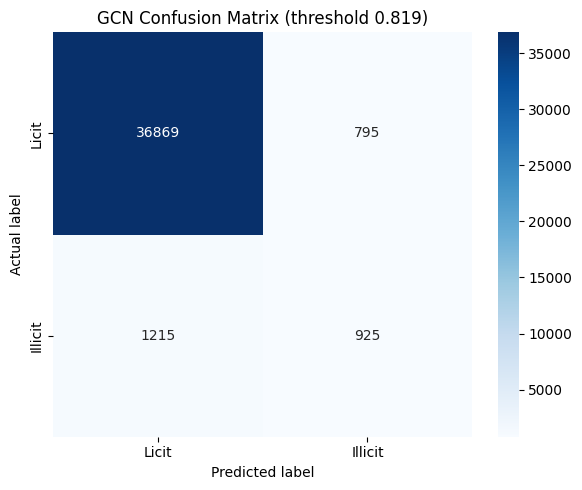

In [49]:
plot_confusion("GCN", gcn_res, "Blues", "gcn_confusion_matrix.png")

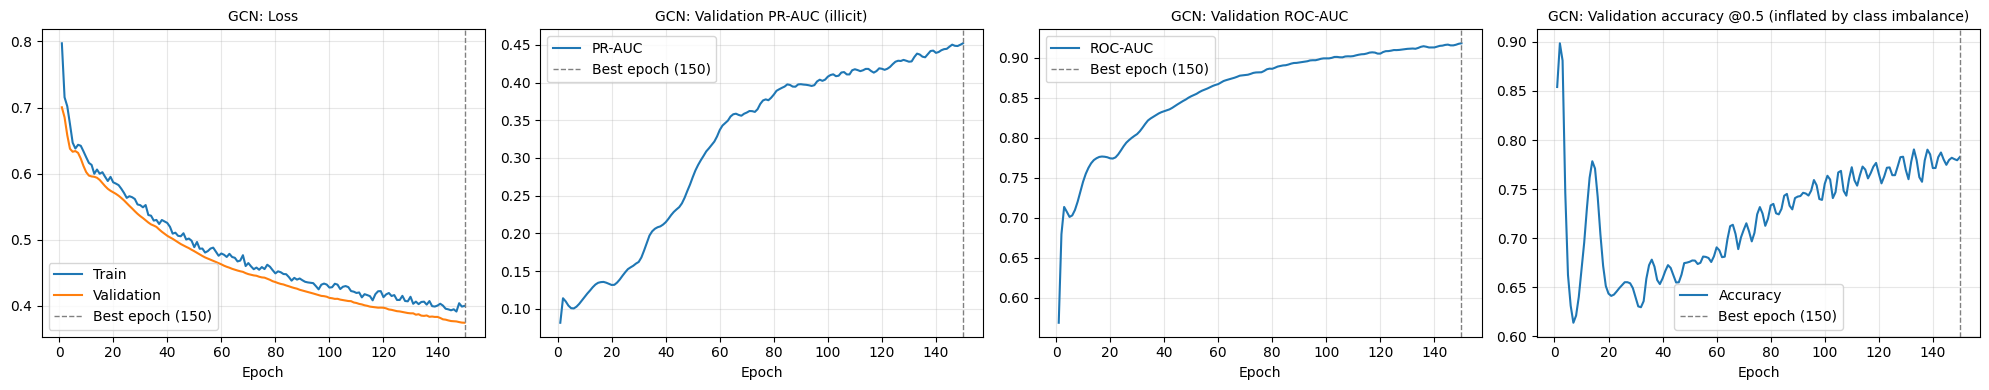

In [50]:
plot_history("GCN", gcn_history, gcn_best_epoch, "gcn_training_curves.png")

# GraphSAGE

In [51]:
set_seed(SEED)
sage_model = GNN("sage", data.num_features, HIDDEN, 2, DROPOUT)
sage_model, sage_history, sage_best_epoch = train_model(
    "GraphSAGE", sage_model, data, class_weights, MODEL_PATH / "best_graphsage_model.pt"
)

GraphSAGE | epoch 001 | loss 0.7671 | val loss 0.7687 | val ROC-AUC 0.8252 | val PR-AUC 0.1859 | 25s
GraphSAGE | epoch 010 | loss 0.4406 | val loss 0.4284 | val ROC-AUC 0.9075 | val PR-AUC 0.4403 | 141s
GraphSAGE | epoch 020 | loss 0.3743 | val loss 0.3438 | val ROC-AUC 0.9286 | val PR-AUC 0.5353 | 279s
GraphSAGE | epoch 030 | loss 0.3326 | val loss 0.3046 | val ROC-AUC 0.9424 | val PR-AUC 0.6101 | 382s
GraphSAGE | epoch 040 | loss 0.3050 | val loss 0.2787 | val ROC-AUC 0.9521 | val PR-AUC 0.6539 | 467s
GraphSAGE | epoch 050 | loss 0.2784 | val loss 0.2603 | val ROC-AUC 0.9592 | val PR-AUC 0.6859 | 551s
GraphSAGE | epoch 060 | loss 0.2651 | val loss 0.2473 | val ROC-AUC 0.9621 | val PR-AUC 0.7013 | 662s
GraphSAGE | epoch 070 | loss 0.2652 | val loss 0.2420 | val ROC-AUC 0.9657 | val PR-AUC 0.7255 | 765s
GraphSAGE | epoch 080 | loss 0.2710 | val loss 0.2354 | val ROC-AUC 0.9660 | val PR-AUC 0.7230 | 890s
GraphSAGE | epoch 090 | loss 0.2509 | val loss 0.2303 | val ROC-AUC 0.9686 | val PR

## Evaluate GraphSAGE

In [52]:
sage_res = evaluate_gnn("GraphSAGE", sage_model, data)

GraphSAGE: threshold 0.8217 (chosen on validation, val F1 0.7201)
GraphSAGE test ROC-AUC: 0.9742 | test PR-AUC: 0.7942

              precision    recall  f1-score   support

       Licit       0.98      0.99      0.99     37664
     Illicit       0.76      0.69      0.73      2140

    accuracy                           0.97     39804
   macro avg       0.87      0.84      0.86     39804
weighted avg       0.97      0.97      0.97     39804



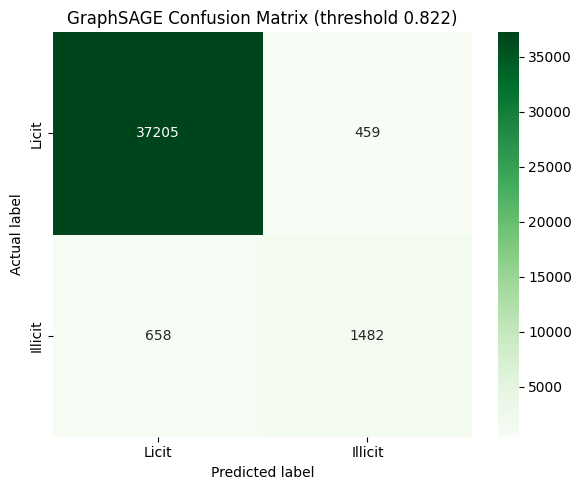

In [53]:
plot_confusion("GraphSAGE", sage_res, "Greens", "graphsage_confusion_matrix.png")

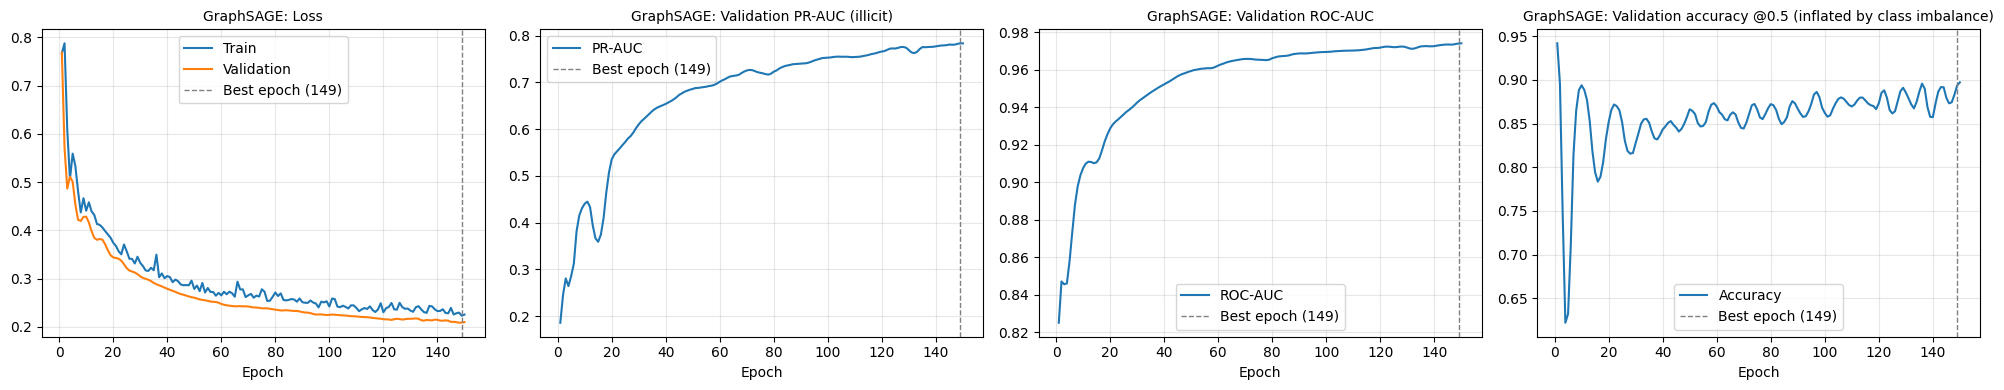

In [54]:
plot_history("GraphSAGE", sage_history, sage_best_epoch, "graphsage_training_curves.png")

# Compare XGBoost vs GCN vs GraphSAGE

All three models use the same 7 features, the same split, the same class-imbalance handling and the same validation-chosen threshold, so the gap between XGBoost and the GNNs is the value added by the graph structure.

In [55]:
all_results = {"XGBoost": xgb_res, "GCN": gcn_res, "GraphSAGE": sage_res}

comparison = (
    pd.DataFrame([r["metrics"] for r in all_results.values()])
    .sort_values("PR-AUC", ascending=False)
    .reset_index(drop=True)
)
print(comparison.round(4).to_string(index=False))
comparison.to_csv(RESULTS_PATH / "gnn_model_comparison.csv", index=False)

# Optional reference: the tuned XGBoost from 03 (it used its own split, so treat as indicative only)
ref_path = RESULTS_PATH / "model_comparison.csv"
if ref_path.exists():
    ref = pd.read_csv(ref_path)
    ref = ref[ref["Model"].astype(str).str.contains("XGB", case=False)]
    if len(ref):
        print("\nReference from 03_train_models (different split):")
        print(ref.round(4).to_string(index=False))

    Model  ROC-AUC  PR-AUC  Illicit Precision  Illicit Recall  Illicit F1  Threshold
GraphSAGE   0.9742  0.7942             0.7635          0.6925      0.7263     0.8217
      GCN   0.9213  0.4711             0.5378          0.4322      0.4793     0.8188
  XGBoost   0.8781  0.4598             0.6738          0.5117      0.5817     0.9017

Reference from 03_train_models (different split):
  Model  Accuracy  Illicit Precision  Illicit Recall  Illicit F1  ROC-AUC  PR-AUC
XGBoost    0.9604             0.6701          0.5173      0.5839   0.8778  0.4622


# Plot comparison

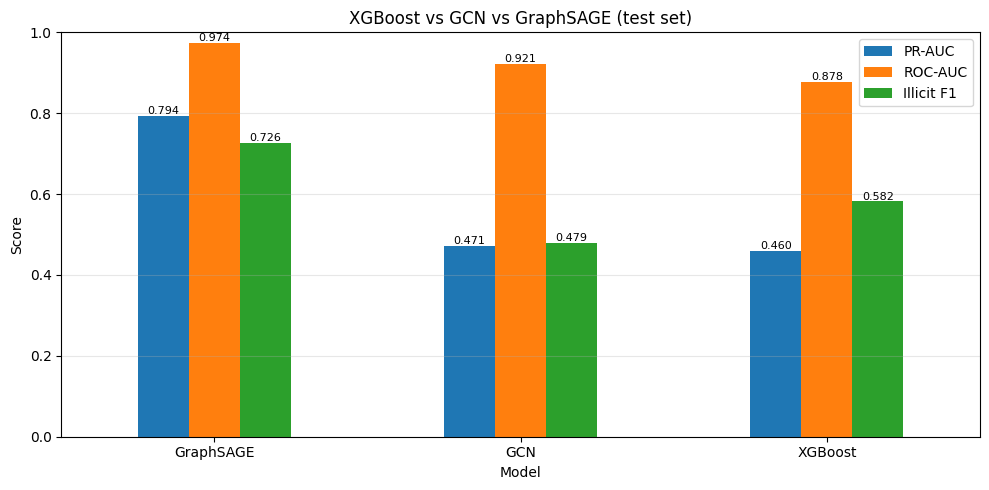

In [56]:
metrics = ["PR-AUC", "ROC-AUC", "Illicit F1"]

ax = comparison.set_index("Model")[metrics].plot(kind="bar", figsize=(10, 5), rot=0, ylim=(0, 1))
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8)
plt.title("XGBoost vs GCN vs GraphSAGE (test set)")
plt.ylabel("Score")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_PATH / "gnn_model_comparison.png", dpi=300)
plt.show()

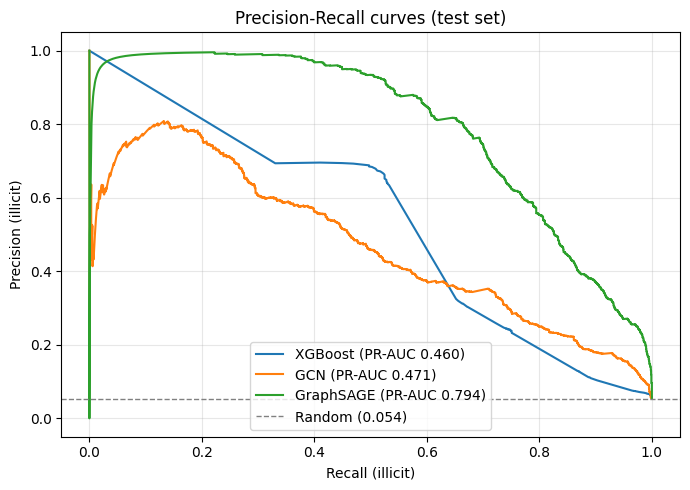

In [57]:
plt.figure(figsize=(7, 5))
for name, res in all_results.items():
    p, r, _ = precision_recall_curve(res["test_true"], res["test_prob"])
    plt.plot(r, p, label=f"{name} (PR-AUC {res['metrics']['PR-AUC']:.3f})")
base_rate = all_results["XGBoost"]["test_true"].mean()
plt.axhline(base_rate, color="gray", ls="--", lw=1, label=f"Random ({base_rate:.3f})")
plt.xlabel("Recall (illicit)")
plt.ylabel("Precision (illicit)")
plt.title("Precision-Recall curves (test set)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_PATH / "gnn_pr_curves.png", dpi=300)
plt.show()

# Save artifacts for `05_results.ipynb`

In [58]:
# Training histories
gcn_history.to_csv(RESULTS_PATH / "gnn_history_gcn.csv", index=False)
sage_history.to_csv(RESULTS_PATH / "gnn_history_graphsage.csv", index=False)

# Test-set predictions from all three models (same wallets, same row order)
addresses = graph_df["address"].to_numpy()
pd.DataFrame({
    "address": addresses[test_idx],
    "y_true": y_all[test_idx],
    "prob_xgboost": xgb_res["test_prob"],
    "prob_gcn": gcn_res["test_prob"],
    "prob_graphsage": sage_res["test_prob"],
}).to_csv(RESULTS_PATH / "gnn_test_predictions.csv", index=False)

# The exact split, so other notebooks / the dashboard can reuse it
split_df = pd.concat([
    pd.DataFrame({"address": addresses[train_idx], "split": "train"}),
    pd.DataFrame({"address": addresses[val_idx], "split": "val"}),
    pd.DataFrame({"address": addresses[test_idx], "split": "test"}),
])
split_df.to_csv(RESULTS_PATH / "gnn_split.csv", index=False)

# Scaler + XGBoost baseline
import joblib
joblib.dump(scaler, MODEL_PATH / "gnn_feature_scaler.joblib")
xgb.save_model(MODEL_PATH / "xgb_baseline_gnn_split.json")

print("Saved to", RESULTS_PATH.resolve(), "and", MODEL_PATH.resolve())

Saved to D:\FraudRing-GNN\outputs\results and D:\FraudRing-GNN\outputs\models
